# Notebook 03 - feature engineering
Turns the clean lap table into a model-ready table. Reads `data/clean_laps.csv.gz` plus the qualifying laps, race session info and corner maps that notebook 01 downloaded; writes `data/model_table.csv.gz`. All the logic lives in `f1lap.features`.

Our first iteration used 6 numeric features plus one-hot compound and team. The problem with leaning on one-hot team identity is that it *names* a car instead of *measuring* it, and a name carries no information about this season. That's exactly what breaks when the regulations change: "Aston Martin" meant a midfield car in 2023 and a back-marker in 2026. So the new features are mostly **measurements that get re-taken every weekend** (qualifying pace, gaps, recent pace), which is the core idea we test in notebooks 05-06.

**Leakage rule for every feature:** a feature for lap L may only use information available when lap L *starts*. Nothing from lap L itself, later laps, or the race result. Qualifying happens before the race, so it's always allowed.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.clean import load_raw, load_session_info, load_quali
from f1lap.features import (build_model_table, circuit_features, quali_features, race_context,
                            encode_features, FEATURE_GROUPS)

pd.set_option('future.no_silent_downcasting', True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEASONS = [2022, 2023, 2024, 2025, 2026]
clean = pd.read_csv('data/clean_laps.csv.gz')
raw = load_raw(SEASONS)                  # every lap, incl. pit and safety-car laps (gaps need all cars)
info = load_session_info(SEASONS)        # race date, round, circuit key, scheduled laps
quali = load_quali(SEASONS)              # every qualifying lap
circuits = circuit_features(SEASONS)     # per-race corner-map summary
df = build_model_table(clean, raw, info, quali, circuits)
print('clean laps:', clean.shape, '-> model table:', df.shape)

clean laps: (90488, 31) -> model table: (90488, 57)


### 1. The features
| Group | Feature | What it is | Why it's leakage-free |
|---|---|---|---|
| base | `tyre_age` | laps on this set of tyres (incl. any used in qualifying) | known at lap start |
| base | `fuel_proxy` | scheduled race laps minus current lap, i.e. laps of fuel on board | from the scheduled distance, not the laps actually run |
| base | `stint` | which stint this is | known at lap start |
| base | `position` | running position **at the start of the lap** (end of the previous one) | the first iteration used the end-of-lap position, which an overtake *during* the lap changes, so it leaked; fixed here |
| base | `air_temp_c`, `track_temp_c` | weather at this lap | exogenous, not driven |
| base | `compound`, `team_lineage` | one-hot tyre and car identity | known before the race |
| quali | `quali_gap_pct` | driver's best qualifying lap vs pole (%) | qualifying is before the race |
| quali | `team_quali_gap_pct` | the team's best car vs pole (%): **car pace measured this weekend** | as above |
| quali | `teammate_quali_gap_pct` | driver vs teammate (% of pole): same car, so it isolates the driver | as above |
| quali | `quali_rank` | knockout order: furthest session reached, then time in it | as above |
| quali | `quali_speed_trap_delta` | speed-trap reading on the best lap vs the field median (kph): straight-line speed | as above |
| driver | `racecraft` | average positions gained (qualifying rank minus finish) over the driver's previous 10 races | uses earlier races only |
| race | `gap_ahead_s`, `gap_behind_s` | time to the car one place ahead / behind when the lap starts | from the previous lap's timing line |
| race | `pos_vs_quali` | qualifying rank minus current position (+ = ahead of where they qualified) | both known at lap start |
| race | `recent_pace` | driver's median lap over the previous 5 laps minus the field's | previous laps only, picked with per-lap rules (no stint medians, which would peek ahead) |
| race | `stint_lap`, `tyre_fresh` | laps since this stint began; new vs used set | known at lap start |
| circuit | `lap_length_m`, `n_corners`, `frac_straight`, `longest_straight_m` | circuit character from the corner map, so the model can describe even an unseen track | static per circuit |
| weather | `humidity`, `wind_speed`, `track_temp_delta` | more conditions; track temperature change since the start | exogenous |

Sector times and speed traps from the race itself are **not** features: they're outcomes of the lap we're predicting. We keep them for analysis in notebook 07.

### 2. Validating the new sources
**Circuits.** Our circuit labels come from event names with the 2026 relocations patched by hand. The session info carries an official circuit key, so we can check the patch: every circuit name should map to exactly one key and vice versa.

In [2]:
pairs = df[['circuit', 'circuit_key']].drop_duplicates()
print('circuits:', pairs.circuit.nunique(), '| keys:', pairs.circuit_key.nunique(), '| pairs:', len(pairs))
assert pairs.circuit.is_unique and pairs.circuit_key.is_unique

circuits: 26 | keys: 26 | pairs: 26


One-to-one, so the hand-patched names (Madrid, Sepang, Barcelona vs Spanish) are right.

**Qualifying.** Ranking by best lap is wrong in a knockout format: in 2022 Brazil, Verstappen set the fastest lap of the session in dry Q1/Q2, but Magnussen took pole in a wet Q3. So `quali_rank` sorts by furthest session reached, then lap time within it. We check it against poles we know for certain. Eight late-2024 sessions have no Q1/Q2/Q3 labels in the data; for those we rank purely by best lap.

In [3]:
qf = quali_features(quali)
known_poles = {(2022, 'São Paulo'): 'MAG', (2022, 'Hungarian'): 'RUS', (2023, 'Singapore'): 'SAI',
               (2023, 'Las Vegas'): 'LEC', (2023, 'Bahrain'): 'VER', (2024, 'Las Vegas'): 'RUS',
               (2024, 'São Paulo'): 'NOR', (2024, 'Monaco'): 'LEC', (2025, 'Monaco'): 'NOR'}
check = pd.DataFrame([{'race': f'{y} {e}', 'real pole': d,
                       'our rank 1': qf[(qf.season == y) & (qf.event == f'{e} Grand Prix') & (qf.quali_rank == 1)].driver.iloc[0]}
                      for (y, e), d in known_poles.items()])
check['match'] = check['real pole'] == check['our rank 1']
assert check.match.all()
print('Drivers whose best lap was beyond 107% of pole (pace features left missing):',
      int(qf.quali_gap_pct.isna().sum()), 'of', len(qf))
check

Drivers whose best lap was beyond 107% of pole (pace features left missing): 85 of 2289


,race,real pole,our rank 1,match
0,2022 São Paulo,MAG,MAG,True
1,2022 Hungarian,RUS,RUS,True
2,2023 Singapore,SAI,SAI,True
3,2023 Las Vegas,LEC,LEC,True
4,2023 Bahrain,VER,VER,True
5,2024 Las Vegas,RUS,RUS,True
6,2024 São Paulo,NOR,NOR,True
7,2024 Monaco,LEC,LEC,True
8,2025 Monaco,NOR,NOR,True


All nine match, including Magnussen's 2022 Brazil pole. For the pace features we apply F1's own **107% rule**: a best lap slower than 107% of pole isn't representative (a crash, an abort, or wet running, e.g. the soaking 2022 Canadian qualifying), so those drivers get missing qualifying-pace features instead of a fake 30% gap. XGBoost handles missing values natively.

### 3. Leakage test on a real race
The package self-check (`python src/f1lap/features.py`) already proves this on a synthetic race. Here we repeat it on real data: take the 2026 Italian GP, scramble **every outcome from lap 30 onwards** (lap times, timing-line times, positions), rebuild the in-race features, and require lap 30's features to be bit-for-bit identical. If any feature peeked at lap 30 or later, it would change.

In [4]:
rng = np.random.RandomState(0)
race = raw[(raw.season == 2026) & (raw.event == 'Italian Grand Prix')].copy()
L = 30
scrambled = race.copy(); later = scrambled.lap >= L
scrambled.loc[later, 'lap_time_s'] *= rng.uniform(0.9, 1.3, later.sum())
scrambled.loc[later, 'lap_end_time_s'] += rng.uniform(0, 60, later.sum())
scrambled.loc[later, 'position'] = rng.permutation(scrambled.loc[later, 'position'].values)
a = race_context(race).set_index(['driver', 'lap']).sort_index()
b = race_context(scrambled).set_index(['driver', 'lap']).sort_index()
at_L = a.index.get_level_values('lap') == L
pd.testing.assert_frame_equal(a[at_L], b[at_L])
changed_after = (a[~at_L & (a.index.get_level_values('lap') > L)].fillna(-999) != b[~at_L & (b.index.get_level_values('lap') > L)].fillna(-999)).any(axis=1).mean()
print(f'Lap {L} features identical after scrambling laps >= {L}: OK  |  share of later laps whose features changed: {changed_after:.0%}')

Lap 30 features identical after scrambling laps >= 30: OK  |  share of later laps whose features changed: 100%


Lap 30's features don't move at all, while the features of later laps do (as they should, since those laps legitimately depend on laps 30+). So the in-race features only ever look backwards.

### 4. Coverage

In [5]:
feats = [c for g in FEATURE_GROUPS.values() for c in g]
cov = df.groupby('season')[feats].apply(lambda g: g.notna().mean() * 100).T.round(1)
cov.columns = [str(c) for c in cov.columns]
cov

,2022,2023,2024,2025,2026
tyre_age,100.0,100.0,100.0,100.0,100.0
fuel_proxy,100.0,100.0,100.0,100.0,100.0
stint,100.0,100.0,100.0,100.0,100.0
position,100.0,100.0,100.0,100.0,100.0
air_temp_c,100.0,100.0,100.0,100.0,100.0
track_temp_c,100.0,100.0,100.0,100.0,100.0
quali_gap_pct,92.6,97.3,99.2,98.5,98.6
team_quali_gap_pct,95.0,98.5,99.7,99.5,99.1
teammate_quali_gap_pct,90.2,95.8,98.2,96.4,97.1
quali_rank,99.7,99.9,99.7,99.5,99.1


**Coverage.** Almost everything is above 95%. The gaps are all explainable:
- `gap_ahead_s` is missing ~5% of the time because the leader has no car ahead (one driver in twenty).
- `racecraft` needs at least 3 earlier races, so it's thin at the very start of 2022 (where our data begins) and for rookies.
- The 2026 circuit features are missing for Madrid and Sepang, whose corner maps are empty in the source data, and `frac_straight` / `longest_straight_m` for a few races with inconsistent section data.

XGBoost learns a default direction for missing values at every split, so we don't impute. The physics baseline only uses `tyre_age`, `fuel_proxy` and `compound`, which are complete.

### 5. Do the new features carry signal, and did that change in 2026?
A first look before any model: the correlation of each feature with the target, in the training era vs 2026.

In [6]:
pre, new = df.season < 2026, df.season == 2026
corr = pd.DataFrame({'2022-2025': df[pre][feats].corrwith(df[pre].lap_delta_s),
                     '2026': df[new][feats].corrwith(df[new].lap_delta_s)}).round(3)
corr['change'] = corr['2026'] - corr['2022-2025']
corr.sort_values('change', ascending=False)

,2022-2025,2026,change
team_quali_gap_pct,0.344,0.677,0.333
quali_gap_pct,0.360,0.679,0.319
racecraft,0.062,0.312,0.250
quali_rank,0.429,0.671,0.242
position,0.442,0.682,0.240
gap_ahead_s,-0.175,0.027,0.202
gap_behind_s,-0.093,0.056,0.149
tyre_fresh,0.026,0.164,0.138
recent_pace,0.410,0.532,0.122
stint,-0.435,-0.323,0.112


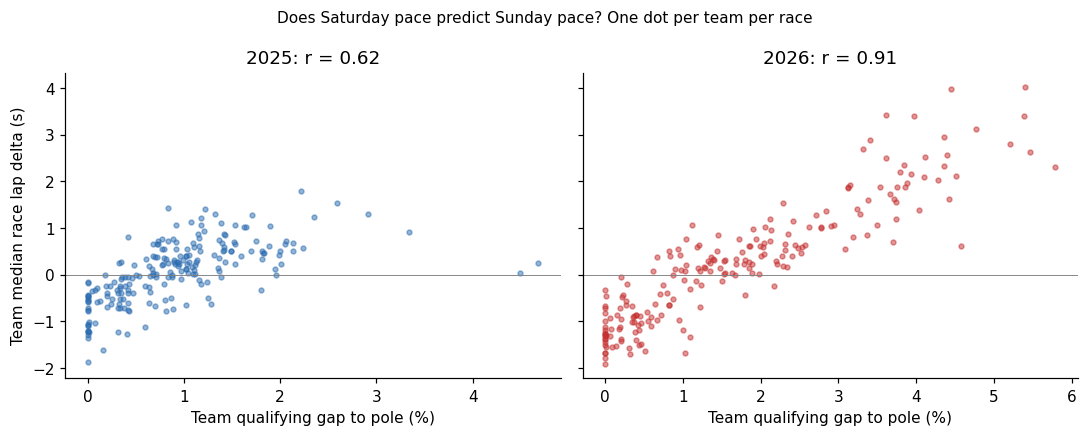

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, y in zip(axs, [2025, 2026]):
    d = df[df.season == y]
    t = d.groupby(['event', 'team_lineage']).agg(q=('team_quali_gap_pct', 'first'), race=('lap_delta_s', 'median')).dropna()
    r = t.q.corr(t.race)
    ax.scatter(t.q, t.race, s=10, alpha=.5, color='#c53030' if y == 2026 else '#2b6cb0')
    ax.set_title(f'{y}: r = {r:.2f}'); ax.set_xlabel('Team qualifying gap to pole (%)'); ax.axhline(0, color='grey', lw=.6)
axs[0].set_ylabel('Team median race lap delta (s)')
fig.suptitle('Does Saturday pace predict Sunday pace? One dot per team per race', fontsize=10)
plt.tight_layout(); plt.savefig('figures/10_quali_vs_race_pace.png', dpi=150); plt.show()

**Figure 10.** This is the single most important picture in the feature work. In 2025 a team's qualifying gap already tells you a lot about its race pace (r = 0.62), but the whole field sits within ~3% of pole and the cloud is wide. In 2026 the field spreads out to ~6% and the relationship becomes almost a straight line (**r = 0.91**): **Saturday pace became a far stronger predictor of Sunday pace**. That's exactly the information our first model was missing. It only knew the team's *name*, so it couldn't know that Aston Martin and Cadillac were seconds off the pace in 2026, while a model that reads qualifying is told so every weekend. `recent_pace` and `position` also correlate more strongly in 2026, for the same reason: with a more spread-out field, who's fast stays fast.

The circuit and weather features barely correlate with the target on their own, which makes sense: the target is relative to the race median, so anything that's the same for every car in a race cancels out. They can still matter through interactions (e.g. tyre wear depending on track temperature), which the ablation in notebook 04 will tell us.

### 6. Save the model table

In [8]:
df.to_csv('data/model_table.csv.gz', index=False)
X = encode_features(df, groups=list(FEATURE_GROUPS))
print('Saved data/model_table.csv.gz', df.shape, '| full feature matrix:', X.shape)

Saved data/model_table.csv.gz (90488, 57) | full feature matrix: (90488, 39)
